In [3]:
import numpy as np
import scipy.stats

import matplotlib.pyplot as plt

In [4]:
title = "# week 6 - Exercises: Nested sampling and slice sampling"
# Print title and setup TeX defs for both KaTeX and MathJax
import bayesian_stats_course_tools
bayesian_stats_course_tools.misc.display_markdown_and_setup_tex(title)

import matplotlib.style
matplotlib.style.use("bayesian_stats_course_tools.light")

# week 6 - Exercises: Nested sampling and slice sampling

<!-- Define LaTeX macros -->
$\def\E{\operatorname{E}}$
$\def\Var{\operatorname{Var}}$
$\def\Cov{\operatorname{Cov}}$
$\def\dd{\mathrm{d}}$
$\def\ee{\mathrm{e}}$
$\def\Norm{\mathcal{N}}$
$\def\Uniform{\mathcal{U}}$
$\def\GP{\mathcal{GP}}$

<!-- MathJax needs them to be defined again for the non-inline environment -->
$$\def\E{\operatorname{E}}$$
$$\def\Var{\operatorname{Var}}$$
$$\def\Cov{\operatorname{Cov}}$$
$$\def\dd{\mathrm{d}}$$
$$\def\ee{\mathrm{e}}$$
$$\def\Norm{\mathcal{N}}$$
$$\def\Uniform{\mathcal{U}}$$
$$\def\GP{\mathcal{GP}}$$

We use the two targets from last week: the 1D Gamma distribution from the lecture and the 2D Gaussian from the Metropolis-Hastings exercise.

In [5]:
# 1D target from the lecture
target_distr_1d = scipy.stats.gamma(a=3, scale=1/3)

# 2D Gaussian from the Metropolis-Hastings exercise
sigma_x = 1
sigma_y = 2
rho = 0.7

mean = np.array([1, 0.5])
cov = np.array([[sigma_x**2, sigma_x*sigma_y*rho],
                [sigma_x*sigma_y*rho, sigma_y**2]])

bivariate_normal = scipy.stats.multivariate_normal(mean=mean, cov=cov)

# Exact samples, to compare your samplers against
np.random.seed(42)
true_samples = bivariate_normal.rvs(size=10_000)

### Exercise 0: Why slice sampling?

*Nothing to implement here: read this and run the cell below.*

Last week we saw two ways to sample from a distribution $p(x)$:
- **Rejection sampling** gives independent samples, but needs a proposal $q$ and a constant $M$ with $Mq(x) > p(x)$ everywhere. In many dimensions almost every point is rejected.
- **Metropolis-Hastings** works in many dimensions, but you have to choose the proposal width. Too small, and the chain moves very slowly; too large, and almost every jump is rejected. The right width depends on $p$, which you do not know beforehand.

**Slice sampling** keeps the Markov chain approach of Metropolis-Hastings, but removes most of the tuning:
- It uses the same idea as rejection sampling: points spread uniformly under the curve $p(x)$ give samples of $p$.
- Each step picks a random height $u$ below $p(x_t)$, then a new point $x_{t+1}$ from the *slice*, where $p(x) > u$ (see the plot below).
- The interval that searches for the slice adapts by itself: it grows if it is too small and shrinks if it is too large. The step size $w$ only changes the speed, not the result.
- No step is wasted: the chain always moves to a new point.

**When to use it:** problems with a few to a moderate number of parameters, when you do not want to tune a proposal. It is also used inside nested sampling codes to find new live points (Exercises 3 and 4).

**When not:** for strongly correlated parameters, updating one coordinate at a time is slow. For very many parameters, methods that use gradients, like Hamiltonian Monte Carlo, work better.

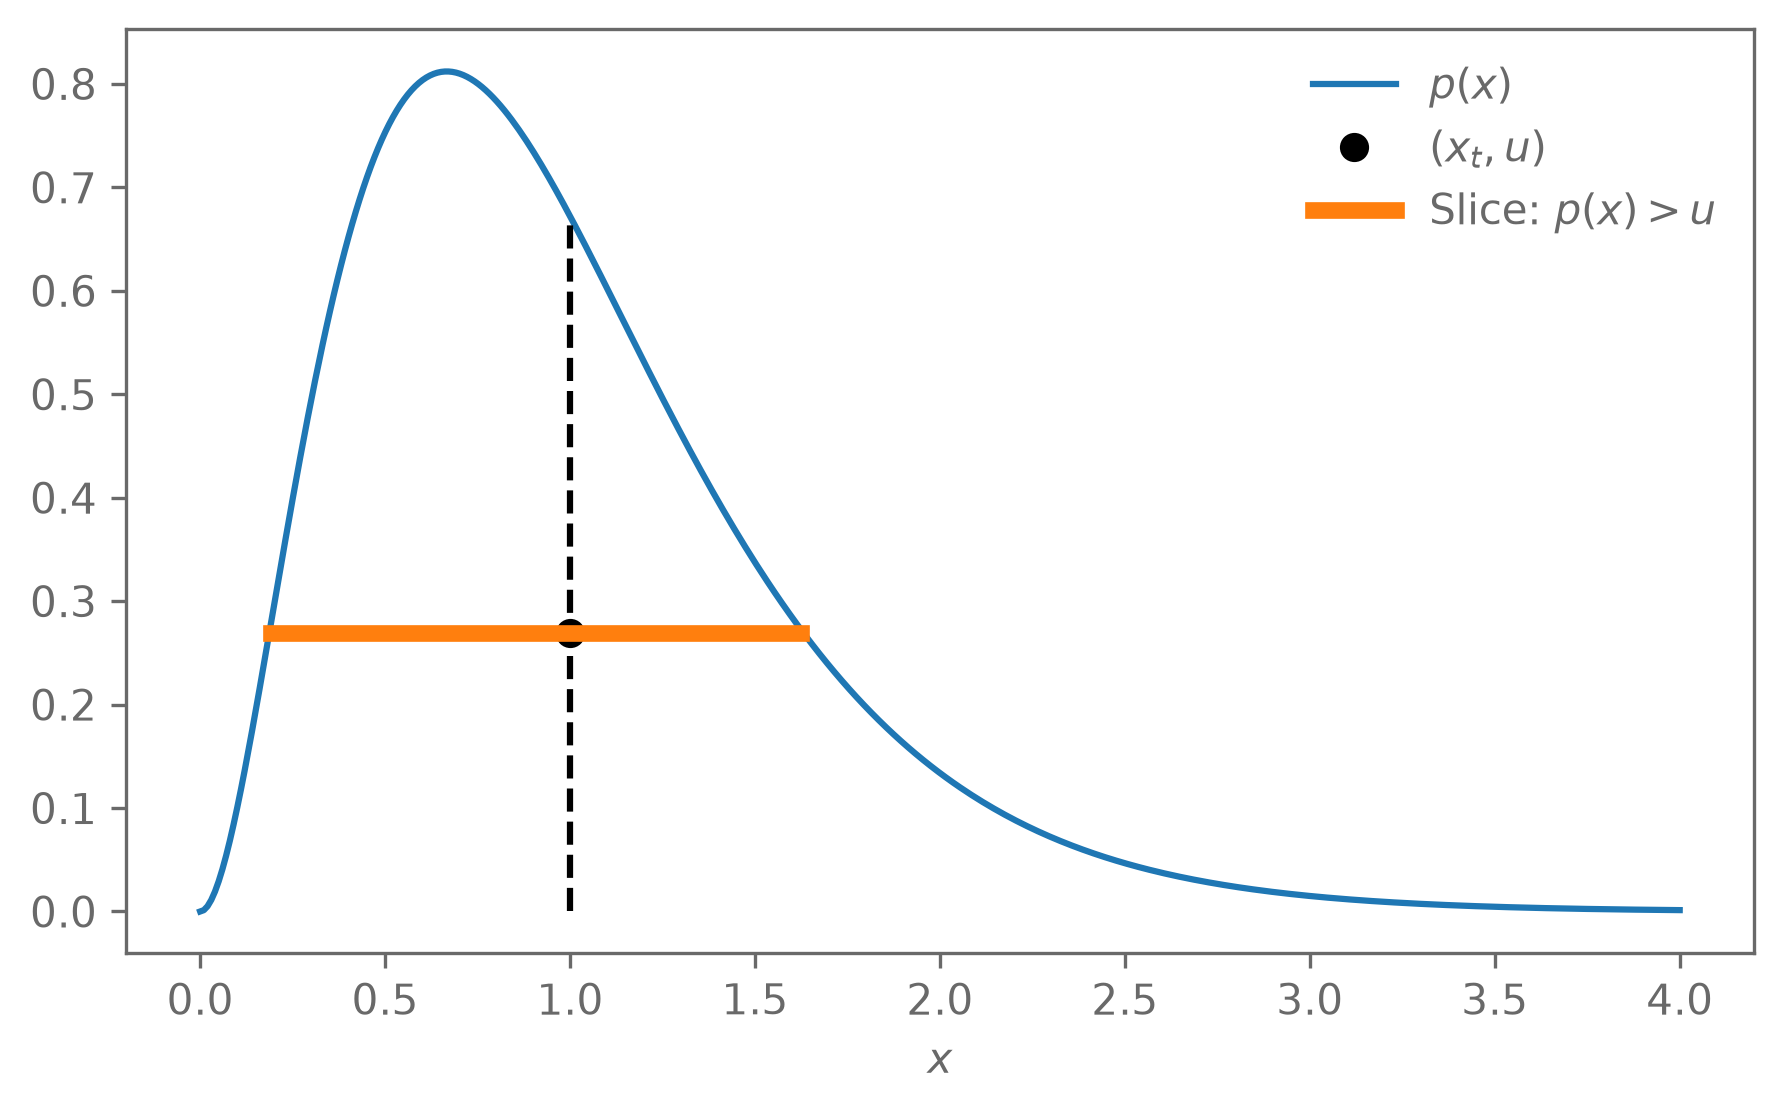

In [6]:
grid = np.linspace(0, 4, 400)
p = target_distr_1d.pdf(grid)

x_t = 1.0                          # current point of the chain
u = 0.4*target_distr_1d.pdf(x_t)   # a height below p(x_t)
in_slice = p > u                   # the slice: all x where p(x) > u

plt.plot(grid, p, label="$p(x)$")
plt.vlines(x_t, 0, target_distr_1d.pdf(x_t), color="k", ls="--")
plt.plot(x_t, u, "ko", label="$(x_t, u)$")
plt.plot(grid[in_slice], np.full(np.sum(in_slice), u), c="C1", lw=4,
         label="Slice: $p(x) > u$")
plt.xlabel("$x$")
plt.legend(frameon=False);

### Exercise 1: Slice sampling

- Implement your own slice sampler and sample from the 1D Gamma distribution. Compare a histogram of the samples to the PDF.
- How does the step size $w$ change the result? Try $w = 0.01, 1, 100$.

In [38]:
def slice_sampling(target_distr, n_steps, step_size, x0):
    accepted_samples = np.empty((n_steps,x0.size))
    accepted_u = np.empty((n_steps,x0.size))
    u_distr = scipy.stats.uniform(0,1.0)
    x_t = x0

    for i in range(n_steps):
        # sample u
        u = u_distr.rvs() * target_distr.pdf(x_t)

        # find the interval [x_l,x_r]
        r = u_distr.rvs()
        x_l = x_t - r * step_size
        x_r = x_t + (1 - r) * step_size
        while target_distr.pdf(x_l) >= u:
            x_l -= step_size
        while target_distr.pdf(x_r) >= u:
            x_r += step_size

        # draw new candidate
        while True:
            x = np.random.uniform(x_l,x_r)
            if target_distr.pdf(x) > u:
                break
            elif x > x_t:
                x_r = x
            else:
                x_l = x

        # accept sample
        accepted_samples[i] = x
        accepted_u[i] = u
        x_t = x

    return accepted_samples, accepted_u


(array([0.14884441, 0.32559716, 0.62328598, 0.74422207, 0.90236926,
        0.89306649, 0.94888314, 0.65119431, 0.71631374, 0.58607488,
        0.49304712, 0.46513879, 0.27908328, 0.25117495, 0.27908328,
        0.15814719, 0.2325694 , 0.10233053, 0.05581666, 0.04651388,
        0.06511943, 0.12093609, 0.01860555, 0.0372111 , 0.06511943,
        0.0372111 , 0.        , 0.02790833, 0.        , 0.        ,
        0.        , 0.00930278, 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.00930278, 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.00930278]),
 array([0.08184204, 0.18933683, 0.29683163, 0.40432642, 0.51182122,
        0.61931602, 0.72681081, 0.83430561, 0.94180041, 1.0492952 ,
        1.15679   , 1.2642848 , 1.37177959, 1.47927439, 1.58676918,
        1.69426398, 1.80175878, 1.90925357, 2.01674837, 2.12424317,
        2.23173796, 2.33923276, 2.44672756, 2.

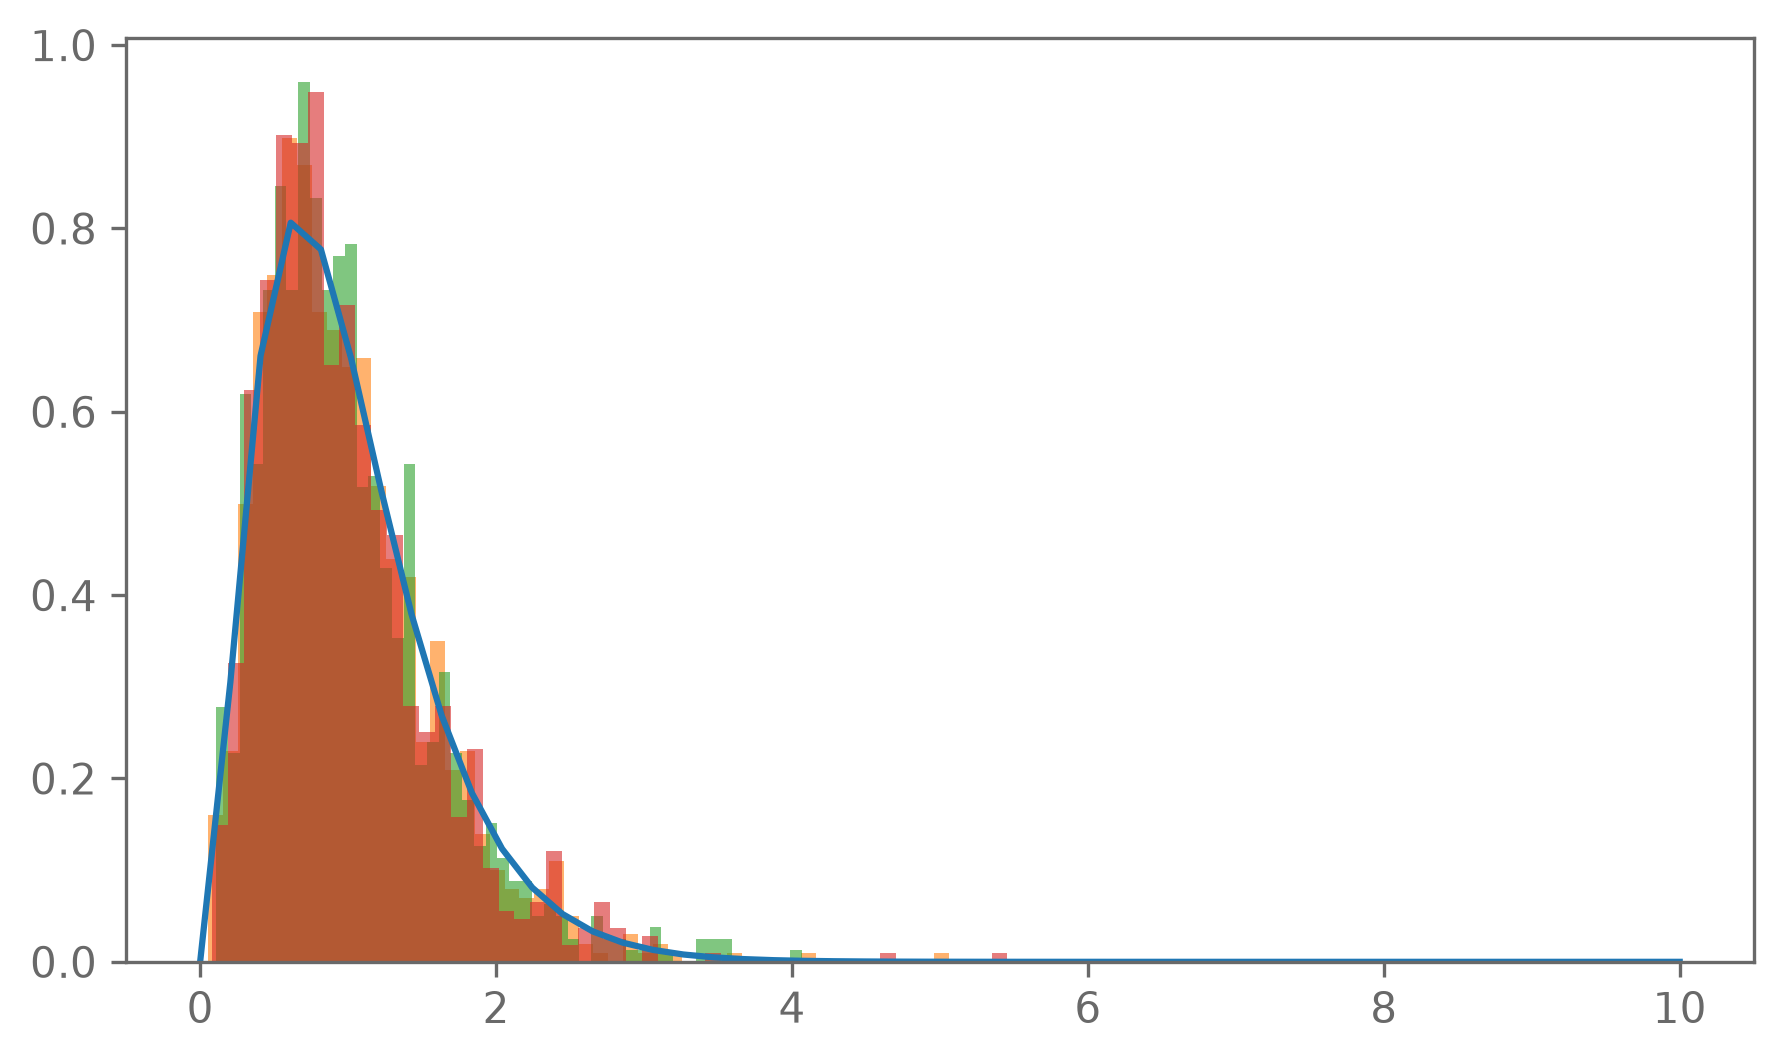

In [43]:
x0 = np.array([3.0])

x_samples1, _ = slice_sampling(target_distr_1d,1000,0.01,x0)
x_samples2, _ = slice_sampling(target_distr_1d,1000,1,x0)
x_samples3, _ = slice_sampling(target_distr_1d,1000,0.1,x0)
x = np.linspace(0.0,10.0)


plt.plot(x,target_distr_1d.pdf(x))
plt.hist(x_samples1,bins = 50, density = True, alpha=0.6)
plt.hist(x_samples2,bins = 50, density = True, alpha=0.6)
plt.hist(x_samples3,bins = 50, density = True, alpha=0.6)
#plt.plot(x_samples, u_samples, ls=' ',marker = 'x')


### Exercise 2: Burn-in and auto-correlation

- Run your Metropolis-Hastings sampler (from week 5) and your slice sampler on the 1D Gamma distribution, starting far in the tail, e.g. at $x = 10$.
- Plot the chains. How long is the burn-in?
- After removing the burn-in, compute the auto-correlation time of each chain with `emcee.autocorr.integrated_time`. Which sampler gives more independent samples?

In [55]:
n_evals = 0

def log_p_gamma(x):
    """Log PDF of the Gamma target. Also counts the number of calls."""
    global n_evals
    n_evals += 1
    return target_distr_1d.logpdf(x)


def metropolis_hastings(log_p, x0, step, n):
    """Metropolis-Hastings in 1D with a Gaussian proposal of width step around the current point."""
    x = x0
    log_p_x = log_p(x)
    samples = np.zeros(n)
    n_accept = 0
    for i in range(n):
        # Propose a new point around the current one
        x_new = x + step*np.random.normal()
        log_p_new = log_p(x_new)

        # Accept with probability min(1, p(x_new)/p(x))
        if np.log(np.random.uniform()) < log_p_new - log_p_x:
            x = x_new
            log_p_x = log_p_new
            n_accept += 1
        samples[i] = x
    print(f"Acceptance rate: {n_accept/n:.2f}")
    return samples

In [2]:
'''x0 = np.array([10.0])
x_linspace = np.linspace(0,10.0,100)
proposal_distr = scipy.stats.norm()

MH_chain,_ = metropolis_hastings(log_p_gamma,x0,step=1,n=100)
SS_chain,_ = slice_sampling(target_distr_1d,100,0.1,x0)

plt.hist(SS_chain,density=True,alpha=0.6,label='Slice Sampling')
plt.hist(MH_chain,density=True,alpha=0.6,label='Metropolis Hastings')
plt.plot(x_linspace,target_distr_1d.pdf(x_linspace),label='Target Distribution')
plt.legend()'''

"x0 = np.array([10.0])\nx_linspace = np.linspace(0,10.0,100)\nproposal_distr = scipy.stats.norm()\n\nMH_chain,_ = metropolis_hastings(log_p_gamma,x0,step=1,n=100)\nSS_chain,_ = slice_sampling(target_distr_1d,100,0.1,x0)\n\nplt.hist(SS_chain,density=True,alpha=0.6,label='Slice Sampling')\nplt.hist(MH_chain,density=True,alpha=0.6,label='Metropolis Hastings')\nplt.plot(x_linspace,target_distr_1d.pdf(x_linspace),label='Target Distribution')\nplt.legend()"

### Exercise 3: Nested sampling

- Implement your own nested sampling routine for $n$ dimensions. Use rejection sampling from the prior to find new live points, as in the lecture.
- Compute the evidence $Z$ for the 2D Gaussian likelihood with a uniform prior on $[-7, 7]^2$. Show that the exact answer is $Z \approx 1/14^2$ and compare.

In [ ]:
def nested_sampling(log_L,prior_sample,n_live,tol=0.01):
    # draw n_live points
    live_points = prior_sample(n_live)
    log_cutoffs = []
    tries_total = []
    log_Z = 1
    t = n_live/(n_live + 1)
    i = 0

    while True:
        i += 1
        # finding the theta with the lowest likelihood from our samples
        lowest = np.argmin([log_L(theta) for theta in live_points])
        log_L_star = log_L[live_points[lowest]]
        log_cutoffs.append(log_L_star)

        # replace the lowest point with a theta of higher likelihood
        #tries = 0
        while True:
            candidate = prior_sample(1)
            #tries += 1
            if log_L(candidate) > log_L_star:
                live_points[lowest] = candidate
                break
        #tries_total.append(tries)

        log_Z = np.logaddexp(log_Z,)


    return



### Exercise 4: emcee and dynesty

This is the main exercise of this week. We use the 2D Gaussian with a uniform prior on $[-7, 7]^2$.

- Sample the 2D Gaussian with `emcee`, starting all walkers close to $(5, -5)$. Plot the chains of the walkers. How long is the burn-in? Compute the auto-correlation time with `sampler.get_autocorr_time()`, then remove the burn-in and thin the chain.
- Sample the 2D Gaussian with `dynesty`. Look at `results.summary()` and at `dynesty.plotting.runplot`. What does the run plot show?
- Compare the samples to `true_samples` in a corner plot.
- Compare $\ln Z$ from `dynesty` to the exact value and to your own nested sampler.
- How many likelihood evaluations did `emcee`, `dynesty`, and your nested sampler need?
- Run `dynesty` with $n_\mathrm{live} = 50, 200, 1000$. How do the uncertainty on $\ln Z$ and the number of likelihood evaluations change?
- `emcee` and `dynesty` give the same posterior, but only `dynesty` gives $\ln Z$. To see why, add a constant (e.g. 10) to your log posterior and run `emcee` again with the same seed. Does anything change? What happens to $\ln Z$ in `dynesty` if you instead make the prior box twice as wide, $[-14, 14]^2$?

### Exercise 5 (Bonus): Model comparison

Go back to the line-fitting exercise and take the data in `lectures/data/linear_fits/data_2.txt`. Compare two models:

$$
\begin{aligned}
    M_1:&\quad \mu(x) = mx + b \\
    M_2:&\quad \mu(x) = ax^2 + bx + c
\end{aligned}
$$

Use the Gaussian likelihood $y_i\sim\mathcal{N}(\mu(x_i), \sigma_{y_i}^2)$ and uniform priors $\mathcal{U}(-3, 3)$ on all parameters.

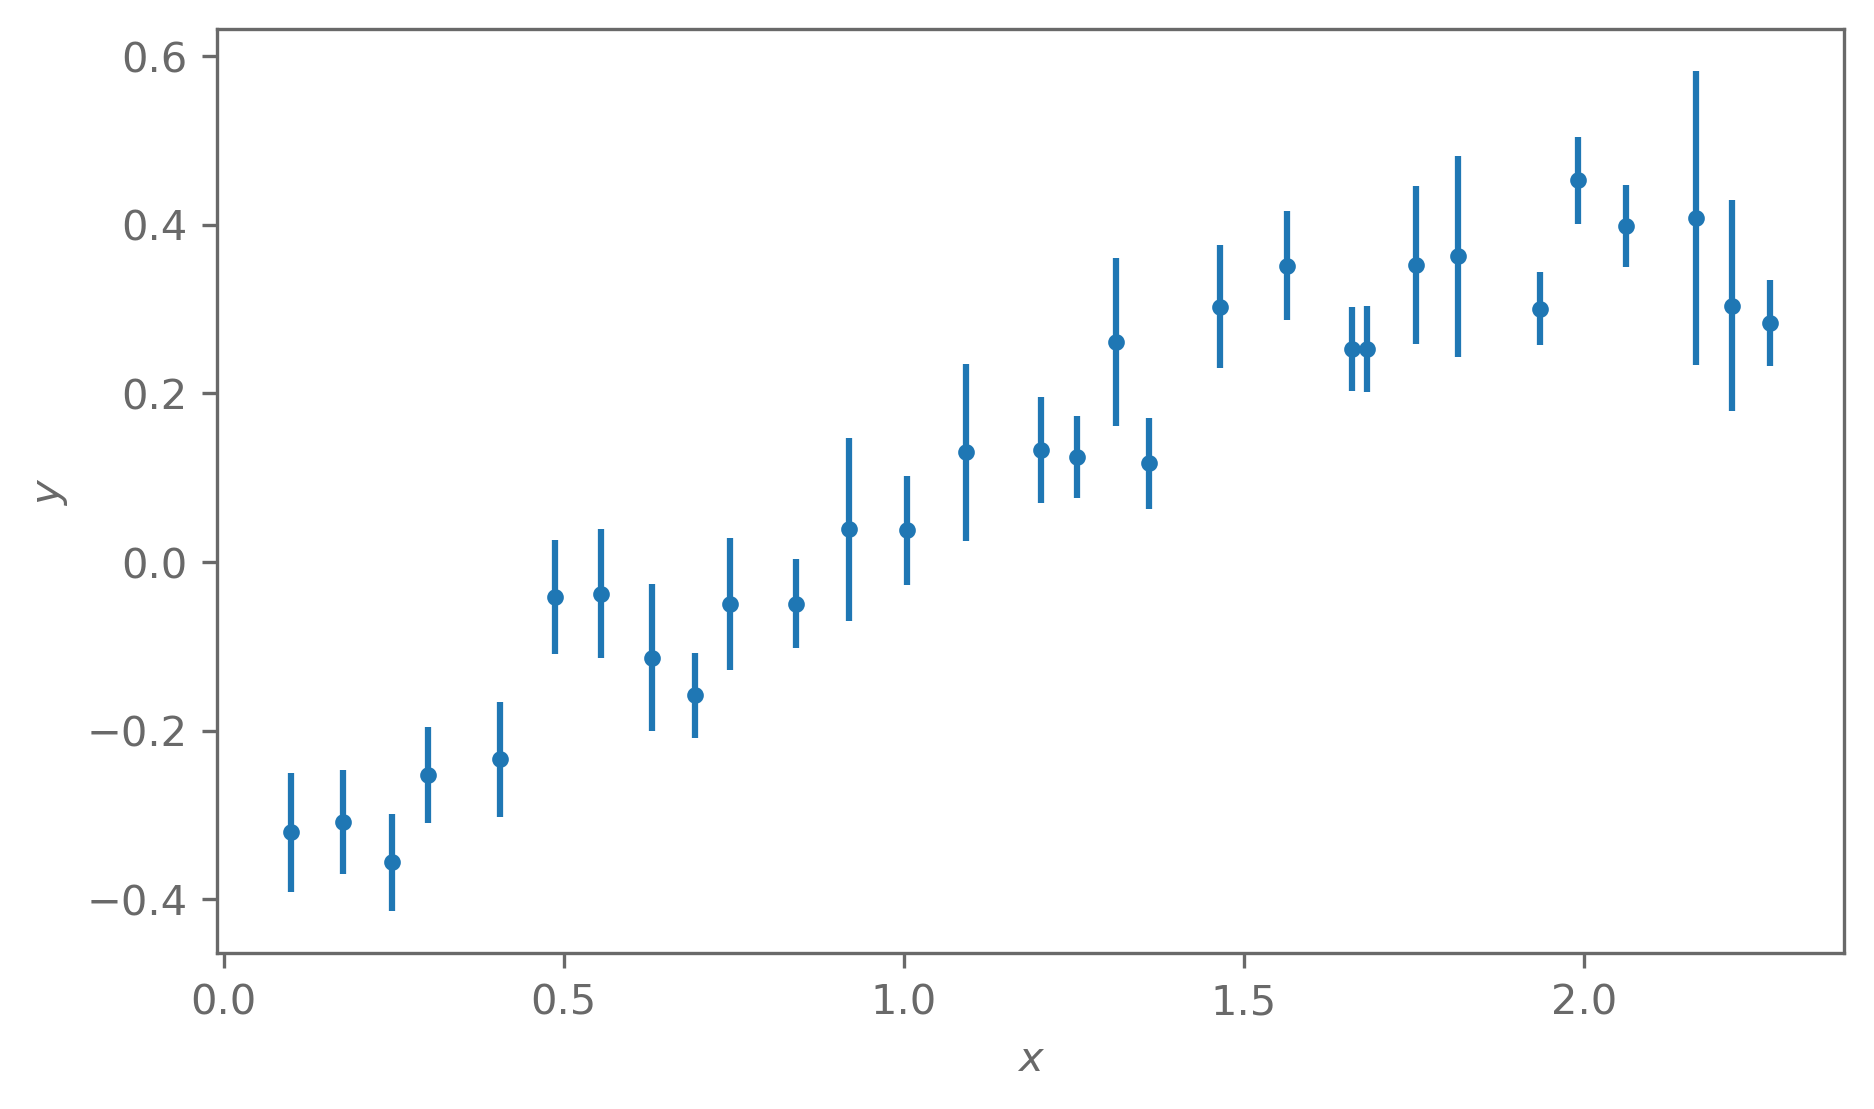

In [10]:
x, y, y_err = np.loadtxt("../lectures/data/linear_fits/data_2.txt", unpack=True)

plt.errorbar(x, y, y_err, fmt=".")
plt.xlabel("$x$")
plt.ylabel("$y$");

- Use `dynesty` to compute the evidence of each model. Which model is preferred by the data, and how strongly?
- Repeat with `data_0.txt`. Which model is preferred now?
- Widen the prior on $a$ to $\mathcal{U}(-30, 30)$. How do the posterior and the Bayes' ratio change?